[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/action0.ipynb)


In [1]:
# Start with a fresh Python kernel (the equivalent of Clear["Global`*"]).
# The following cell defines all objects used by this example.

Нагадаємо, що під час руху тіла в полі тяжіння проєкції швидкості тіла, кинутого під кутом $\alpha$ до горизонту, описуються виразами:

$$
{v}_{x}\left(t\right)={v}_{0}\cos{\alpha} , {v}_{y}\left(t\right)={v}_{0}\sin{\alpha} -gt
$$

Рівняння траєкторії в параметричному поданні:

$$
x\left(t\right)={v}_{0}t \cos{\alpha} , y\left(t\right)={v}_{0}t \sin{\alpha} -\frac{{gt}^{2}}{2}
$$

У явному вигляді:

$$
y\left(x\right)=\tan{\alpha}  x-\frac{{gx}^{2}}{2 {v}_{0}^{2}\cos^{2}{\alpha} }
$$

Парабола, що відповідає «справжній» траєкторії з повною безрозмірною енергією $E=1$ у полі тяжіння ($m=1$, $g=1$):

$$
U\left(y\right)=y
$$

Тоді $v_0=\sqrt{2}$, і траєкторія визначається рівнянням ($L$ — дальність):

$$
{y}_{0}\left(x\right)=\tan{\alpha}  x-\frac{{gx}^{2}}{4 \cos^{2}{\alpha} }, L=2 \sin{2\alpha} 
$$

Дослідимо поведінку дії вздовж довільної траєкторії між $x=0$ і $x=L$,

$$
S\left[y\left(x\right)\right]={\int }_{0}^{L}p ds={\int }_{0}^{L}\sqrt{2\left(1-U\left[y\left(x\right)\right]\right)\left(1+{\left(y'\right)}^{2}\right)} dx
$$

яка мало відхиляється від дійсної. Наприклад, візьмемо сімейство

$$
y\left(x,\varepsilon \right)={y}_{0}\left(x\right)+\varepsilon  {\sum }_{k=1}^{2}\frac{\sin{\left(\pi *k\right)}}{{k}^{2}}, \left|\varepsilon \right|<1
$$

| Traj | Function y(x, ε) | Action |
|---|---|---:|
| Real | $- 1.38196601125011 x^{2} + 1.38196590631813 x$ | 2.55917243 |
| Pert1 | $- 1.38196601125011 x^{2} + 1.38196590631813 x + 0.1 \sin{\left(\pi x \right)} + 0.025 \sin{\left(2 \pi x \right)}$ | 2.56637164 |
| Pert2 | $- 1.38196601125011 x^{2} + 1.38196590631813 x - 0.1 \sin{\left(\pi x \right)} - 0.025 \sin{\left(2 \pi x \right)}$ | 2.56983691 |

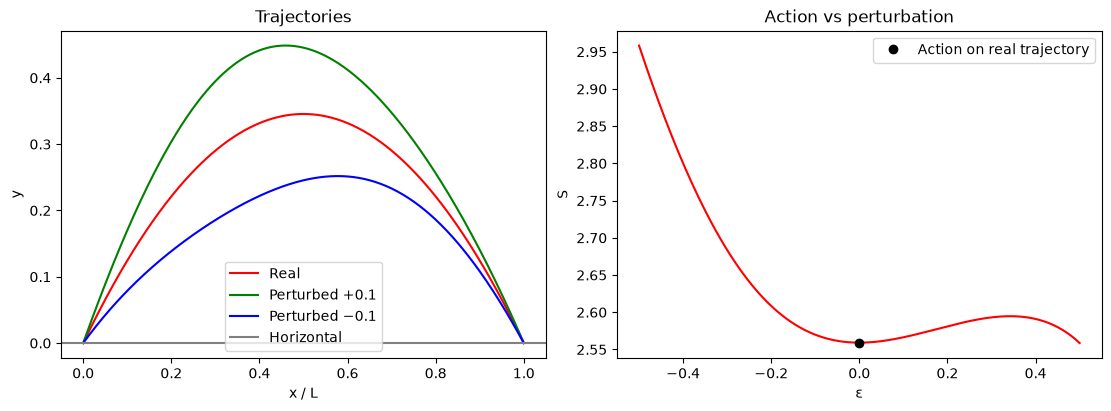

In [2]:
"""Python counterpart of the original stationary-action Manipulate cell.

The notebook builder copies this code into each notebook: no helper-file import
is required by students or Colab.
"""
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import quad
from scipy.optimize import brentq
from IPython.display import display, Markdown
import ipywidgets as widgets

v0 = np.sqrt(2.0)


def real(x, ang):
    return x * (np.tan(ang) - x / (2 * v0**2 * np.cos(ang)**2))


def l0(ang):
    return v0**2 * np.sin(2 * ang)


def imp(f):
    # Real momentum only where U(y) <= E. Do not clip forbidden paths.
    return v0 * np.sqrt(1 - f)


def f1(x, eps, ang):
    return real(np.asarray(x) * l0(ang), ang) + eps * sum(
        np.sin(k * np.pi * np.asarray(x)) / k**2 for k in (1, 2)
    )


def df1(x, eps, ang):
    length = l0(ang)
    return length * np.tan(ang) - np.asarray(x) * length**2 / (v0**2 * np.cos(ang)**2) + eps * sum(
        np.pi * np.cos(k * np.pi * np.asarray(x)) / k for k in (1, 2)
    )


def maximum_height(eps, ang):
    grid = np.linspace(0, 1, 129)
    deriv = df1(grid, eps, ang)
    candidates = [0.0, 1.0]
    for a, b, da, db in zip(grid[:-1], grid[1:], deriv[:-1], deriv[1:]):
        if da == 0:
            candidates.append(a)
        elif da * db < 0:
            candidates.append(brentq(lambda s: df1(s, eps, ang), a, b))
    return float(np.max(f1(np.array(candidates), eps, ang)))


def act(eps, ang):
    if not 0 < ang < np.pi / 2:
        raise ValueError('The launch angle must lie between 0 and pi/2.')
    if maximum_height(eps, ang) > 1:
        return np.nan  # The source square root becomes complex here.
    length = l0(ang)
    value, error = quad(
        lambda s: imp(f1(s, eps, ang)) * np.sqrt(1 + (df1(s, eps, ang) / length)**2),
        0, 1, epsabs=1e-10, epsrel=1e-10, limit=200,
    )
    return length * value


def show_demo(ang=np.pi/5):
    x = np.linspace(0, 1, 401)
    eps_values = np.linspace(-0.5, 0.5, 201)
    actions = np.array([act(eps, ang) for eps in eps_values])
    q = sp.Symbol('x', real=True)
    length = l0(ang)
    baseline = length*q*sp.Float(np.tan(ang), 5) - (length*q)**2/(2*v0**2*np.cos(ang)**2)
    table = ['| Traj | Function y(x, ε) | Action |', '|---|---|---:|']
    for label, eps in [('Real', 0.0), ('Pert1', 0.1), ('Pert2', -0.1)]:
        expr = baseline + eps*(sp.sin(sp.pi*q) + sp.sin(2*sp.pi*q)/4)
        value = act(eps, ang)
        result = f'{value:.8f}' if np.isfinite(value) else 'Not real (y > E)'
        table.append(f'| {label} | ${sp.latex(expr)}$ | {result} |')
    display(Markdown('\n'.join(table)))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
    for eps, color, label in [(0, 'red', 'Real'), (0.1, 'green', 'Perturbed +0.1'), (-0.1, 'blue', 'Perturbed −0.1')]:
        axes[0].plot(x, f1(x, eps, ang), color=color, label=label)
    axes[0].axhline(0, color='gray', label='Horizontal')
    axes[0].set(xlabel='x / L', ylabel='y', title='Trajectories')
    axes[0].legend()
    axes[1].plot(eps_values, actions, color='red')
    axes[1].plot(0, act(0, ang), 'ko', label='Action on real trajectory')
    axes[1].set(xlabel='ε', ylabel='S', title='Action vs perturbation')
    axes[1].legend()
    if np.any(~np.isfinite(actions)):
        axes[1].text(0.02, 0.02, 'Gaps: paths enter y > E', transform=axes[1].transAxes)
    plt.show()


# A saved static example remains visible in notebook viewers without widgets.
show_demo()
angle_slider = widgets.FloatSlider(value=np.pi/5, min=np.pi/5, max=np.pi/2.5,
                                  step=0.01, description='α (rad)', continuous_update=False)
interactive_output = widgets.interactive_output(show_demo, {'ang': angle_slider})
display(widgets.VBox([angle_slider, interactive_output]))


Як бачимо, за малих кутів $\alpha$ реальна траєкторія відповідає мінімуму дії. Це пояснюється тим, що в цьому випадку кінетична енергія значно більша за потенціальну, функціонал дії близький до функціонала геометричної довжини, а траєкторія, грубо кажучи, близька до прямої — траєкторії вільного руху. Зі зростанням кута вплив потенціальної енергії посилюється, і на значній частині траєкторії сповільнення стає суттєвим. Тому проста картина мінімальної довжини вже не відповідає дійсності. Проте фізична траєкторія залишається стаціонарною точкою функціонала: точкою перегину або максимуму.